NEXT WORD PREDICTION USING WORD2VEC + LSTM
1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Dataset downloaded successfully!
Total characters: 1115394

Total sentences: 29563

Dataset split:
Training: 23650
Validation: 2956
Testing: 2957

Training Word2Vec...
Word2Vec training completed!
Word2Vec vocabulary: 6051

Vocabulary size: 5000
Embedding matrix shape: (5000, 100)
Words with pretrained embeddings: 4998

Sequence preparation completed!
Training shape: (134698, 10)
Validation shape: (16920, 10)
Testing shape: (17050, 10)

Building LSTM model...


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 10, 100)        │       500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 128)            │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5000)           │       645,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,278,760 (4.88 MB)

 Trainable params: 1,278,760 (4.88 MB)

 Non-trainable params: 0 (0.00 B)


Model compiled successfully!

Starting LSTM training...
Epoch 1/8
527/527 ━━━━━━━━━━━━━━━━━━━━ 77s 142ms/step - accuracy: 0.0575 - loss: 6.4095 - val_accuracy: 0.0989 - val_loss: 5.8206 - learning_rate: 0.0010
Epoch 2/8
527/527 ━━━━━━━━━━━━━━━━━━━━ 80s 139ms/step - accuracy: 0.0943 - loss: 5.8401 - val_accuracy: 0.1209 - val_loss: 5.5575 - learning_rate: 0.0010
Epoch 3/8
527/527 ━━━━━━━━━━━━━━━━━━━━ 82s 139ms/step - accuracy: 0.1099 - loss: 5.5932 - val_accuracy: 0.1251 - val_loss: 5.4197 - learning_rate: 0.0010
Epoch 4/8
527/527 ━━━━━━━━━━━━━━━━━━━━ 84s 142ms/step - accuracy: 0.1167 - loss: 5.4312 - val_accuracy: 0.1284 - val_loss: 5.3558 - learning_rate: 0.0010
Epoch 5/8
527/527 ━━━━━━━━━━━━━━━━━━━━ 73s 139ms/step - accuracy: 0.1227 - loss: 5.3025 - val_accuracy: 0.1307 - val_loss: 5.3218 - learning_rate: 0.0010
Epoch 6/8
527/527 ━━━━━━━━━━━━━━━━━━━━ 84s 142ms/step - accuracy: 0.1272 - loss: 5.1930 - val_accuracy: 0.1343 - val_loss: 5.3024 - learning_rate: 0.0010
Epoch 7/8
527/527 ━

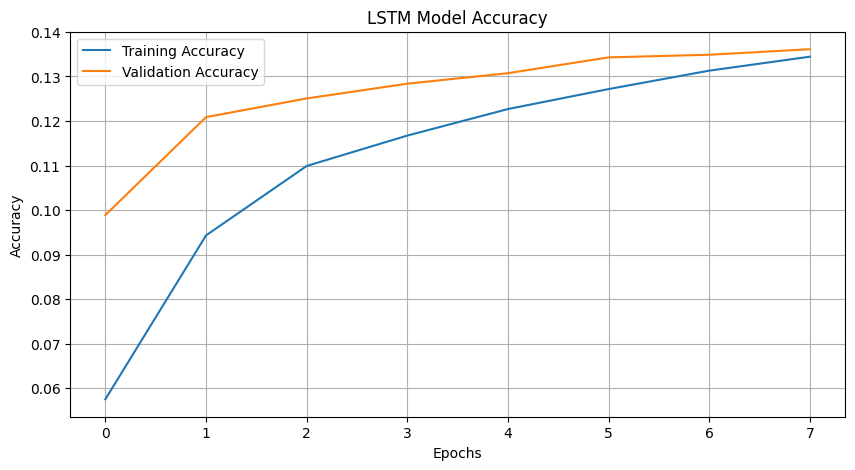

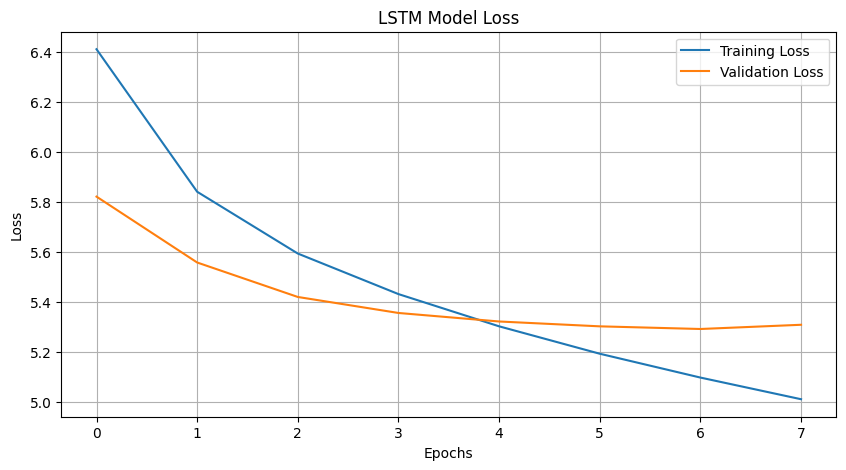


Evaluating model on test data...
533/533 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.1341 - loss: 5.3136

FINAL MODEL RESULTS
----------------------------------------
Test Loss: 5.3136
Test Accuracy: 13.41 %

NEXT WORD PREDICTION TEST
----------------------------------------

Input: the king of
Predicted next words:
york: 5.17%
hereford: 4.12%
the: 3.69%
my: 2.52%
his: 2.36%

Input: to be or not
Predicted next words:
to: 4.59%
a: 4.28%
so: 3.03%
in: 2.82%
i: 2.54%

Input: i will never
Predicted next words:
be: 4.31%
have: 2.22%
see: 2.01%
do: 1.98%
not: 1.85%

PROJECT COMPLETED SUCCESSFULLY!

Saved files:
- next_word_lstm.keras
- word2vec.model
- tokenizer.pkl


In [24]:

# ============================================================
# NEXT WORD PREDICTION USING WORD2VEC + LSTM
# COMPLETE PROJECT - SINGLE CELL
# ============================================================

# 1. INSTALL LIBRARIES
%pip install -q gensim tensorflow scikit-learn matplotlib

# 2. IMPORT LIBRARIES
import re
import os
import pickle
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("=" * 60)
print("NEXT WORD PREDICTION USING WORD2VEC + LSTM")
print("=" * 60)

# 3. DOWNLOAD DATASET
dataset_url = (
    "https://raw.githubusercontent.com/"
    "karpathy/char-rnn/master/data/"
    "tinyshakespeare/input.txt"
)

dataset_path = tf.keras.utils.get_file(
    "tinyshakespeare.txt",
    dataset_url
)

with open(dataset_path, "r", encoding="utf-8") as file:
    raw_text = file.read()

print("\nDataset downloaded successfully!")
print("Total characters:", len(raw_text))

# 4. TEXT PREPROCESSING
raw_sentences = re.split(
    r'[\n]+|(?<=[.!?])\s+',
    raw_text.lower()
)

tokenized_sentences = []

for sentence in raw_sentences:

    tokens = re.findall(r"[a-z']+", sentence)

    if len(tokens) >= 2:
        tokenized_sentences.append(tokens)

print("\nTotal sentences:", len(tokenized_sentences))

# 5. SPLIT DATASET BY SENTENCE
train_sentences, temp_sentences = train_test_split(
    tokenized_sentences,
    test_size=0.20,
    random_state=42
)

val_sentences, test_sentences = train_test_split(
    temp_sentences,
    test_size=0.50,
    random_state=42
)

print("\nDataset split:")
print("Training:", len(train_sentences))
print("Validation:", len(val_sentences))
print("Testing:", len(test_sentences))

# 6. TRAIN WORD2VEC
print("\nTraining Word2Vec...")

word2vec_model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=15,
    seed=42
)

print("Word2Vec training completed!")
print("Word2Vec vocabulary:", len(word2vec_model.wv))

# 7. CREATE TOKENIZER AND VOCABULARY
MAX_VOCAB_SIZE = 5000
EMBEDDING_DIM = 100
MAX_SEQUENCE_LENGTH = 10

tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(
    [" ".join(sentence) for sentence in train_sentences]
)

vocab_size = min(
    MAX_VOCAB_SIZE,
    len(tokenizer.word_index) + 1
)

print("\nVocabulary size:", vocab_size)

# 8. CREATE WORD2VEC EMBEDDING MATRIX
embedding_matrix = np.zeros(
    (vocab_size, EMBEDDING_DIM),
    dtype=np.float32
)

matched_words = 0

for word, index in tokenizer.word_index.items():

    if index >= vocab_size:
        continue

    if word in word2vec_model.wv:
        embedding_matrix[index] = word2vec_model.wv[word]
        matched_words += 1

print("Embedding matrix shape:", embedding_matrix.shape)
print("Words with pretrained embeddings:", matched_words)

# 9. CREATE INPUT SEQUENCES AND TARGET WORDS
def create_sequences(sentences):

    sequences = []

    encoded_sentences = tokenizer.texts_to_sequences(
        [" ".join(sentence) for sentence in sentences]
    )

    for sentence in encoded_sentences:

        for i in range(1, len(sentence)):

            sequence = sentence[
                max(0, i - MAX_SEQUENCE_LENGTH):i + 1
            ]

            sequences.append(sequence)

    padded = pad_sequences(
        sequences,
        maxlen=MAX_SEQUENCE_LENGTH + 1,
        padding="pre",
        truncating="pre"
    )

    X_data = padded[:, :-1]
    y_data = padded[:, -1]

    return X_data, y_data


X_train, y_train = create_sequences(train_sentences)
X_val, y_val = create_sequences(val_sentences)
X_test, y_test = create_sequences(test_sentences)

print("\nSequence preparation completed!")
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

# 10. BUILD LSTM MODEL
print("\nBuilding LSTM model...")

model = Sequential([

    Input(shape=(MAX_SEQUENCE_LENGTH,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        mask_zero=True,
        trainable=True
    ),

    LSTM(128),

    Dropout(0.3),

    Dense(128, activation="relu"),

    Dropout(0.2),

    Dense(vocab_size, activation="softmax")
])

model.summary()

# 11. COMPILE MODEL
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nModel compiled successfully!")

# 12. TRAIN MODEL
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

print("\nStarting LSTM training...")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=256,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

# 13. VISUALIZE ACCURACY
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 14. VISUALIZE LOSS
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# 15. EVALUATE MODEL
print("\nEvaluating model on test data...")

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nFINAL MODEL RESULTS")
print("-" * 40)
print("Test Loss:", round(float(test_loss), 4))
print("Test Accuracy:", round(float(test_accuracy) * 100, 2), "%")

# 16. NEXT WORD PREDICTION FUNCTION
def predict_next_words(input_text, top_k=5):

    input_text = input_text.lower()

    input_tokens = re.findall(
        r"[a-z']+",
        input_text
    )

    encoded = tokenizer.texts_to_sequences(
        [" ".join(input_tokens)]
    )[0]

    encoded = encoded[-MAX_SEQUENCE_LENGTH:]

    padded = pad_sequences(
        [encoded],
        maxlen=MAX_SEQUENCE_LENGTH,
        padding="pre"
    )

    probabilities = model.predict(
        padded,
        verbose=0
    )[0]

    top_indices = np.argsort(probabilities)[::-1]

    results = []

    for index in top_indices:

        word = tokenizer.index_word.get(index)

        if word and word != "<OOV>" and index != 0:

            results.append(
                (word, float(probabilities[index]))
            )

        if len(results) == top_k:
            break

    return results


# 17. TEST PREDICTIONS
print("\nNEXT WORD PREDICTION TEST")
print("-" * 40)

test_inputs = [
    "the king of",
    "to be or not",
    "i will never"
]

for sentence in test_inputs:

    predictions = predict_next_words(sentence)

    print("\nInput:", sentence)
    print("Predicted next words:")

    for word, probability in predictions:
        print(
            f"{word}: {probability * 100:.2f}%"
        )

# 18. SAVE ALL MODELS
output_folder = "Next_Word_Prediction_Models"

os.makedirs(output_folder, exist_ok=True)

model.save(
    os.path.join(output_folder, "next_word_lstm.keras")
)

word2vec_model.save(
    os.path.join(output_folder, "word2vec.model")
)

with open(
    os.path.join(output_folder, "tokenizer.pkl"),
    "wb"
) as file:

    pickle.dump(tokenizer, file)

print("\n" + "=" * 60)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 60)

print("\nSaved files:")
print("- next_word_lstm.keras")
print("- word2vec.model")
print("- tokenizer.pkl")


In [25]:

import ipywidgets as widgets
from IPython.display import display, clear_output

# Sentence input box
sentence_input = widgets.Text(
    value="",
    placeholder="Enter a sentence here...",
    description="Sentence:",
    layout=widgets.Layout(width="80%")
)

# Predict button
predict_button = widgets.Button(
    description="Predict Next Word",
    button_style="success",
    icon="search"
)

# Output area
output = widgets.Output()

# Prediction function
def on_predict_clicked(b):

    with output:
        clear_output()

        sentence = sentence_input.value.strip()

        if not sentence:
            print("Please enter a sentence!")
            return

        predictions = predict_next_words(
            sentence,
            top_k=5
        )

        print("Your sentence:", sentence)
        print("\nPredicted next words:\n")

        for i, (word, probability) in enumerate(predictions, 1):
            print(
                f"{i}. {word} — {probability * 100:.2f}%"
            )

# Connect button
predict_button.on_click(on_predict_clicked)

# Display interface
display(
    widgets.VBox([
        widgets.HTML("<h2>Next Word Prediction System</h2>"),
        sentence_input,
        predict_button,
        output
    ])
)
